In [118]:
import matplotlib.pyplot as plt
import matplotlib.path as mpath
import matplotlib.patches as mpatches


def set_publication_style():
    plt.style.use('default')

    # My custom palette
    publication_settings = {
        "font.family": "sans-serif",
        "font.serif": ["Times New Roman", "DejaVu Serif", "Computer Modern"],
        "font.sans-serif": ["Arial", "DejaVu Sans", "Helvetica"],
        "mathtext.fontset": "stix",

        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "grid.color": "lightgray",

        "font.size": 10,
        "axes.titlesize": 12,
        "axes.labelsize": 11,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "figure.titlesize": 12,

        "figure.dpi": 300,
        "savefig.dpi": 300,
        "savefig.bbox": 'tight',
        "savefig.format": 'pdf',
        "savefig.transparent": False,

        "lines.linewidth": 1.5,
        "lines.markersize": 6,
        "scatter.marker": "o",

        "axes.linewidth": 0.8,
        "axes.grid": False,
        "grid.linewidth": 0.5,
        "grid.alpha": 0.3,

        "image.cmap": "RdBu",

        "legend.frameon": True,
        "legend.framealpha": 0.8,
        "legend.edgecolor": "black",

        "errorbar.capsize": 3,
    }

    plt.rcParams.update(publication_settings)

set_publication_style()

In [111]:
"""
    (I - P) rho = S
    P     transmission portion
    S     injection
    rho   flux carried by narrator
"""

import re
from collections import Counter

import numpy as np
import pandas as pd
import networkx as nx
import scipy.sparse as sp
import scipy.sparse.linalg as spla


# ----------------------------------------------------------------------
# CONFIG
# ----------------------------------------------------------------------
SCHOLARS_PATH = 'all_narrators_global.json'

# HADITH_PATH   = 'sahih_al_bukhari_clean.json'
# HADITH_PATH   = 'sahih_muslim_clean_full.json'
HADITH_PATH   = 'abudawud_clean_full.json'
# HADITH_PATH   = 'nasai_clean_full.json'

GEN_CAP       = 4
PEER_GAP_MAX  = 20.0
MAX_GEN       = 12
WEIGHT_MODE   = 'occurrence'
MAX_HOPS      = 12

_STYLE = {'figure.dpi': 130, 'font.size': 8,
          'axes.spines.top': False, 'axes.spines.right': False}

# ----------------------------------------------------------------------
# GRAPH BUILDER
# ----------------------------------------------------------------------


# We do some cleaning below, death should be ignored though since its not used any most cases not recorded at all
def build_metadata(path=SCHOLARS_PATH):
    meta = pd.read_json(path)
    meta['narrator_id'] = meta['narrator_id'].astype(str)
    meta = meta.drop_duplicates('narrator_id', keep='first')

    def gen_rank(s):
        if s is None or (isinstance(s, float) and np.isnan(s)): return None
        m = re.match(r'^\s*(\d+)', str(s).strip())
        if not m: return None
        k = int(m.group(1))
        return k - 1 if 1 <= k <= MAX_GEN else None

    def death_ah(s):
        if not isinstance(s, str): return np.nan
        nums = [int(x) for x in re.findall(r'\d+', s)]
        if not nums: return np.nan
        ah = [x for x in nums if 0 < x <= 400]
        return float(ah[0]) if ah else float(nums[0])

    meta['gen_rank'] = meta['generation_en'].map(gen_rank)
    meta['death_ah'] = meta['death_year_en'].map(death_ah)
    return meta

# We create the narrator chains by parsing the indices in each hadith
def parse_segments(cell):
    if cell is None or (isinstance(cell, float) and np.isnan(cell)): return []
    if not isinstance(cell, dict): raise TypeError(f"Expected dict, got {type(cell).__name__}")
    segments, cur = [], []
    for x in cell.get('scholar_indices') or []:
        if x is None or x == '' or (isinstance(x, float) and np.isnan(x)):
            if len(cur) > 1: segments.append(cur[::-1])
            cur = []
        else: cur.append(str(x))
    if len(cur) > 1: segments.append(cur[::-1])
    return segments

# Orientation check is redundant, but might be useful just in case, but all of the edges have the same direction
def load_chains(meta, path=HADITH_PATH):
    df = pd.read_json(path)
    df['segments'] = df['transmission_information'].apply(parse_segments)
    hid_col = next((c for c in ('hadith_id', 'id', 'hadith_no', 'reference') if c in df.columns), None)
    if hid_col is None:
        df = df.reset_index().rename(columns={'index': 'auto_hid'})
        hid_col = 'auto_hid'

    gmap = meta.set_index('narrator_id')['gen_rank'].dropna().to_dict()
    inc = dec = 0
    for segs in df['segments']:
        for seg in segs:
            g = [gmap[x] for x in seg if x in gmap]
            if len(g) >= 2:
                inc += g[0] < g[-1]
                dec += g[0] > g[-1]
    orient = dict(increasing=inc, decreasing=dec, reversed=True, margin=abs(inc - dec) / max(inc + dec, 1))
    if dec > inc: raise ValueError(f"orientation assumption violated")
    return df, hid_col, orient


# Actual transmissions
def build_edges(df, hid_col):
    rows, terminal_w, n_hops = [], Counter(), []
    for r in df.itertuples(index=False):
        hid = getattr(r, hid_col)
        for seg in r.segments:
            for p, (a, b) in enumerate(zip(seg, seg[1:])):
                if a != b:
                    rows.append({'hadith_id': hid, 'pos': p, 'teacher': a,
                                 'student': b, 'chain_len': len(seg)})
            terminal_w[seg[-1]] += 1
            n_hops.append(len(seg))

    edges_long = pd.DataFrame(rows)
    w = edges_long.groupby(['teacher', 'student']).size()
    edge_weights = Counter({(t, s): int(c) for (t, s), c in w.items()})
    return edges_long, edge_weights, terminal_w, float(np.mean(n_hops))

# Create a directed-graph, as before death is redundant
def build_graph(edge_weights, meta):
    G = nx.Graph()
    for (a, b), w in edge_weights.items():
        if G.has_edge(a, b): G[a][b]['weight'] += w
        else: G.add_edge(a, b, weight=w)
    nodes = list(G.nodes())
    idx = {v: i for i, v in enumerate(nodes)}
    gmap = meta.set_index('narrator_id')['gen_rank']
    dmap = meta.set_index('narrator_id')['death_ah']
    gen   = np.array([gmap.get(v, np.nan) for v in nodes], dtype=float)
    death = np.array([dmap.get(v, np.nan) for v in nodes], dtype=float)
    return G, nodes, idx, gen, death


# Only vertical gen1 -> gen2 transmission, single generation transmission breaks the acyclic structure, if death dates were correct -
# - it would gratly simplify the process, since we determine generation by maximum and minimum death year for some cohor,
def _classify(ia, ib, gen):
    ga, gb = gen[ia], gen[ib]
    if np.isnan(ga) or np.isnan(gb):
        return 'no_generation', None, None
    if ga == gb:
        return 'lateral_same_gen', None, None
    teacher, student = (ia, ib) if ga < gb else (ib, ia)
    if gen[student] - gen[teacher] > GEN_CAP:
        return 'over_gen_cap', None, None
    return 'kept_by_generation', teacher, student


# Actually drop the lateral edges
def split_edges(edge_weights, idx, gen, death):
    n = len(idx)
    vr, vc, vd = [], [], []
    mass = Counter()
    for (a, b), w in edge_weights.items():
        verdict, teacher, student = _classify(idx[a], idx[b], gen)
        mass[verdict] += w
        if teacher is not None:
            vr.append(student); vc.append(teacher); vd.append(w)
    A_vert = sp.csr_matrix((vd, (vr, vc)), shape=(n, n), dtype=float)
    A_vert.sum_duplicates()
    drops = dict(
        lateral=mass['lateral_same_gen'],
        no_generation=mass['no_generation'],
        over_gen_cap=mass['over_gen_cap'],
    )
    return A_vert, drops


# We create the absorbing OMEGA row here, and append n + 1 for the new dimensions, and normalization and flag orphans, which are just
# narrators with zero column sum, meaning transmission never reached the end
def build_operators(A_vert, nodes, idx, terminal_w):
    n = len(nodes)
    OMEGA = n
    c = A_vert.tocoo()
    r_, c_, d_ = list(c.row), list(c.col), list(c.data)
    terminal_placed = 0.0
    for v, w in terminal_w.items():
        if v in idx:
            r_.append(OMEGA); c_.append(idx[v]); d_.append(float(w))
            terminal_placed += w
    A_aug = sp.csr_matrix((d_, (r_, c_)), shape=(n + 1, n + 1), dtype=float)
    A_aug.sum_duplicates()
    col = np.asarray(A_aug.sum(axis=0)).ravel()
    orphan = (col == 0)
    orphan[OMEGA] = False
    P = A_aug.multiply(1.0 / np.where(col == 0, 1.0, col)).tocsr()
    return P, OMEGA, orphan, terminal_placed

def assert_acyclic(A_vert):
    c = A_vert.tocoo()
    D = nx.DiGraph()
    D.add_nodes_from(range(A_vert.shape[0]))
    D.add_edges_from(zip(c.col.tolist(), c.row.tolist()))
    if not nx.is_directed_acyclic_graph(D):
        raise ValueError("Transmission graph contains a cycle.")
    return nx.dag_longest_path_length(D)


# ----------------------------------------------------------------------
# SYSTEM SOLVERS
# ----------------------------------------------------------------------
def make_source(A_vert, gen, seeding='uniform'):
    """
    Mathematical Formulation:
      Roots (R): R = {u in V : (A^T 1)_u > 0, (A 1)_u = 0}
      Source Vector (S): S_u = 1 (if uniform) OR (A^T 1)_u (if out-strength)
    """
    in_s  = np.asarray(A_vert.sum(axis=1)).ravel()  # In-degree / incoming edge sum: (A 1)_u
    out_s = np.asarray(A_vert.sum(axis=0)).ravel() # Out-degree / outgoing edge sum: (A^T 1)_u
    roots = np.where((in_s == 0) & (out_s > 0))[0]  # Isolate nodes with 0 incoming and >0 outgoing edges

    S = np.zeros(len(gen) + 1)
    S[roots] = 1.0 if seeding == 'uniform' else out_s[roots]
    return S, roots


# Just solves the original flux
def solve_flux(P, S):
    """
      Original Equation: (I - P) rho = S
      Solution via Fundamental Matrix: rho = (I - P)^(-1) S
    """
    N = P.shape[0]
    # Solves the triangular system exactly in one pass via forward substitution
    return spla.spsolve((sp.eye(N, format='csc') - P.tocsc()), S)

# Solves backward and appends +1 for each node, basically a counter, although the results converge later
def downstream_depth(P):
    """
      Depth Recursive Equation: nu = 1 + P^T nu
      Rearranged Linear System: (I - P^T) nu = 1
    """
    N = P.shape[0]
    # Solves backward from the collector using P transpose (upper triangular)
    return spla.spsolve((sp.eye(N, format='csc') - P.T).tocsc(), np.ones(N))


# This can be said to model the evolution of flux over hops, and the actual final result over ||S|| can be said to be the average chain length
def path_decomposition(P, S, max_k=MAX_HOPS):
    """
      Hop Decomposition Series: rho = sum_{k=0}^m R_k
      Iterative Step: R_k = P * R_{k-1}  (where R_0 = S)
    """
    out, v = [], S.copy()
    while v.sum() > 1e-12:
        if len(out) >= max_k: raise RuntimeError("Did not drain; check acyclicity")
        out.append(v.copy())
        v = P.dot(v)  # Advances material forward by one hop: P^k S
    return np.vstack(out)


# Simply how the system conserves flow, except the orphans which are leaks and OMEGA
def edge_flux(P, rho_full, nodes, name_map):
    """
      Kirchhoff:  / Edge Flux: f_{vu} = P_{vu} * rho_u
      Ensures local conservation: sum_v f_{vu} = rho_u
    """
    F = P.multiply(rho_full[np.newaxis, :]).tocoo()
    n = len(nodes)
    lbl = lambda i: 'COLLECTOR' if i >= n else name_map.get(nodes[i], '?')
    return pd.DataFrame({
        'teacher': [lbl(j) for j in F.col],
        'student': [lbl(i) for i in F.row],
        'flux': F.data,
    }).sort_values('flux', ascending=False)


#  ----------------------------------------------------------------------
# 6. ASSEMBLE
#  ----------------------------------------------------------------------
def build_model(seeding='uniform'):
    meta = build_metadata()
    df, hid_col, orient = load_chains(meta)
    edges_long, edge_weights, terminal_w, emp_hops = build_edges(df, hid_col)
    G, nodes, idx, gen, death = build_graph(edge_weights, meta)
    A_vert, drops = split_edges(edge_weights, idx, gen, death)
    longest = assert_acyclic(A_vert)

    P, OMEGA, orphan, terminal_placed = build_operators(A_vert, nodes, idx, terminal_w)
    S, roots = make_source(A_vert, gen, seeding)

    n = len(nodes)
    rho_full = solve_flux(P, S)
    rho, absorbed = rho_full[:n], rho_full[OMEGA]
    RK = path_decomposition(P, S)

    # conservation checks
    stranded = float(rho_full[orphan].sum())
    resid = abs(S.sum() - absorbed - stranded)
    assert resid < 1e-8 * max(S.sum(), 1.0), f"conservation violated: {resid:.3e}"

    nu = downstream_depth(P)
    nu_nodes = np.where(orphan[:n], np.nan, nu[:n])
    mean_len = float(nu @ S) / S.sum()

    name_map = meta.set_index('narrator_id')['name_en']
    kk = np.arange(RK.shape[0])[:, None]
    mass = RK[:, :n].sum(axis=0)
    mean_hops = np.where(mass > 1e-15, (RK[:, :n] * kk).sum(axis=0) / np.where(mass > 1e-15, mass, 1.0), np.nan)

    nodes_df = pd.DataFrame({
        'narrator_id': nodes, 'name_en': [name_map.get(v, '?') for v in nodes],
        'gen': gen, 'death_ah': death, 'flux': rho, 'flux_share': rho / S.sum(),
        'nu_depth': nu_nodes, 'mean_hops': mean_hops, 'orphan': orphan[:n],
    })

    w_vert = float(A_vert.sum())
    total_recorded = w_vert + drops['lateral'] + drops['no_generation'] + drops['over_gen_cap']
    root_gens = gen[roots]

    diag = dict(
        n_nodes=n, n_vertical_edges=int(A_vert.nnz), longest_chain=longest,
        n_roots=len(roots), injected=float(S.sum()),
        absorbed=float(absorbed), stranded=stranded,
        orphan_share=stranded / S.sum() if S.sum() else np.nan,
        unreached=int((rho <= 1e-15).sum()),
        # preprocessing drops, all over a common denominator
        total_recorded=total_recorded,
        lateral_share=drops['lateral'] / total_recorded,
        over_gen_cap_share=drops['over_gen_cap'] / total_recorded,
        no_generation_share=drops['no_generation'] / total_recorded,
        kept_share=w_vert / total_recorded,
        gen_cap=GEN_CAP,
        # root composition
        roots_gen0=int(np.nansum(root_gens == 0)),
        roots_gen_max=float(np.nanmax(root_gens)) if len(root_gens) else np.nan,
        roots_no_gen=int(np.isnan(root_gens).sum()),
        mean_chain_len_model=mean_len - 1.0, mean_chain_len_empirical=emp_hops,
    )

    return dict(meta=meta, hadith=df, P=P, OMEGA=OMEGA, orphan=orphan, S=S, roots=roots,
                rho=rho, rho_full=rho_full, absorbed=absorbed, nu=nu, RK=RK,
                nodes_df=nodes_df, name_map=name_map, diag=diag, gen=gen, nodes=nodes,
                A_vert=A_vert, terminal_w=terminal_w, idx=idx, G=G,
                edges_long=edges_long, edge_weights=edge_weights)


#  ----------------------------------------------------------------------
# 7. ANALYTICS
#  ----------------------------------------------------------------------

# Gets generation layers
def _layers(M):
    gen = M['gen']
    levels = sorted(set(gen[~np.isnan(gen)].astype(int)))
    return {t: np.where(gen == t)[0] for t in levels}, levels

# Here we zero out a certain narrator by DPD, since the system is nillpotent it will zero out all tranmissions and received information,
# then we compare the actual rho to the top narrators, and we compare by simply removing one and the preceedings ones as well, the result is
# interesting cause it can quantify redundancy, meaning how much shared/identical flow are narrators carrying
def ablation(M, K=12, abs_max=0.50, pool_size=60):
    P, OMEGA, n = M['P'], M['OMEGA'], len(M['nodes'])
    N, S = P.shape[0], M['S']
    I = sp.eye(N, format='csc')

    def delivered(rm):
        keep = np.ones(N)
        keep[list(rm)] = 0.0
        D = sp.diags(keep)
        return spla.spsolve(I - (D @ P @ D).tocsc(), S * keep)[OMEGA]

    base = delivered([])
    onward = np.asarray(M['A_vert'].sum(axis=0)).ravel()
    absorb = np.array([M['terminal_w'].get(v, 0) for v in M['nodes']], float)
    abs_frac = absorb / np.maximum(absorb + onward, 1e-12)

    root_set = set(int(r) for r in M['roots'])
    elig = np.array([i for i in range(n)
                     if i not in root_set and abs_frac[i] < abs_max
                     and M['rho'][i] > 1e-12])
    order = [int(x) for x in elig[np.argsort(-M['rho'][elig])]]

    curve = pd.DataFrame([{
        'k': k + 1,
        'i': order[k],
        'name_en': M['nodes_df'].name_en.iloc[order[k]],
        'gen': M['gen'][order[k]],
        'flux_share': M['rho'][order[k]] / M['S'].sum(),
        'solo': 1 - delivered([order[k]]) / base,
        'cumulative': 1 - delivered(order[:k + 1]) / base,
    } for k in range(K)])

    pool = order[:pool_size]
    solo = pd.DataFrame([{'i': c, 'name_en': M['nodes_df'].name_en.iloc[c],
                          'gen': M['gen'][c], 'flux': M['rho'][c],
                          'solo': 1 - delivered([c]) / base} for c in pool])

    top5 = curve.head(5)
    joint = 1 - delivered(top5['i'].tolist()) / base
    agg = dict(base=float(base), n_eligible=len(elig), pool_size=len(pool),
               sum_solo=float(top5.solo.sum()), joint=float(joint),
               overlap=float(top5.solo.sum() - joint))
    return curve, solo, agg


# How much flux per generation
def concentration(M):
    layers, levels = _layers(M)
    def gini(x):
        x = np.sort(np.asarray(x, float))
        if x.sum() <= 0: return np.nan
        i = np.arange(1, len(x) + 1)
        return float((2 * i - len(x) - 1).dot(x) / (len(x) * x.sum()))
    out = []
    for t in levels:
        m = layers[t]
        if len(m) < 5: continue
        f = M['rho'][m]
        if f.sum() <= 0: continue
        o = np.sort(f)[::-1]
        out.append({'gen': t, 'n': len(m), 'gini': gini(f),
                    'top1': o[0] / f.sum(), 'top5': o[:5].sum() / f.sum()})
    return pd.DataFrame(out)

def inflow_by_index(M, v, top=6):
    df = M['nodes_df']
    F = edge_flux(M['P'], M['rho_full'], M['nodes'], M['name_map'])
    student = df.name_en.iloc[v]
    sub = F[F.student == student].copy()
    sub['share'] = sub.flux / sub.flux.sum()
    return student, sub.head(top)[['teacher', 'flux', 'share']]

# Spermann for other graph measures
def centrality_baseline(M, abl):
    from scipy.stats import spearmanr

    _, solo, _ = abl
    c = M['A_vert'].tocoo()
    D = nx.DiGraph()
    D.add_nodes_from(range(M['A_vert'].shape[0]))
    for t, s, w in zip(c.col, c.row, c.data):
        D.add_edge(int(t), int(s), weight=float(w))

    deg  = dict(D.degree(weight='weight'))
    btw  = nx.betweenness_centrality(D, weight=None)
    pr   = nx.pagerank(D, weight='weight')

    idx = solo['i'].tolist()
    cols = {'degree': [deg.get(i, 0) for i in idx],
            'betweenness': [btw.get(i, 0) for i in idx],
            'pagerank': [pr.get(i, 0) for i in idx],
            'flux': M['rho'][idx]}

    for name, vals in cols.items():
        r, p = spearmanr(vals, solo['solo'])
        print(f"  sigma vs {name:12s}  rho = {r: .3f}   (p = {p:.1e})")

    # rank agreement in the top 10 by each measure
    top_sigma = set(solo.nlargest(10, 'solo')['i'])
    for name, vals in cols.items():
        s = pd.Series(vals, index=idx)
        print(f"  top-10 overlap, {name:12s} {len(top_sigma & set(s.nlargest(10).index))}/10")

In [112]:
_KNOWN = {
    'Muhammad ibn Shihab al-Zuhri': 'al-Zuhri',
    'Shu`ba ibn al-Hajjaj al-`Ataki': "Shu`ba",
    'Malik ibn Anas al-Asbahi': 'Malik',
    '`Urwa ibn Az-Zubayr al-Asadi': "`Urwa",
    'Sufyan ibn `Uyayna al-Hilali': 'Ibn `Uyayna',
    'Sufyan ath-Thawri': 'al-Thawri',
    'al-Layth ibn Sa`d al-Fhmi': 'al-Layth',
    'Qutayba ibn Sa`id al-Thaqafi': 'Qutayba',
    '`Ali ibn al-Madini': 'Ibn al-Madini',
    'Msdd ibn Msrhd al-Asadi': 'Musaddad',
    '`Abd Allah ibn Yusuf al-Kla`ai': 'Ibn Yusuf',
}

def short_name(full, seen=None):
    if full in _KNOWN:
        return _KNOWN[full]
    toks = str(full).split()
    nisba = next((t for t in reversed(toks) if t.lower().startswith(('al-', 'ath-', 'az-'))), None)
    if nisba and (seen is None or list(seen).count(nisba) <= 1):
        return nisba
    ism = toks[0] if toks else '?'
    return f"{ism} {nisba}" if nisba else ism

In [113]:
# Most plots were generated with the help of AI, but have been checked for accuracy

def fig_ablation(M, abl, fname='fig_ablation.png', show=True):
    curve, solo, agg = abl
    conc = concentration(M)

    with plt.rc_context(_STYLE):
        fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))

        ax = axs[0]


        ax.plot(curve.k, curve.cumulative, 'o-', ms=4, color='#c44e52',
                label='cumulative')
        ax.plot(curve.k, curve.solo.cumsum(), '^:', ms=4, color='#888',
                label='sum of solo')
        ax.fill_between(curve.k, curve.cumulative, curve.solo.cumsum(),
                        alpha=.12, color='#c44e52')
        ax.legend(frameon=False, fontsize=7)



        ax.fill_between(curve.k, 0, curve.cumulative, alpha=.10, color='#c44e52')
        for r in curve.head(4).itertuples():
            ax.annotate(short_name(r.name_en), (r.k, r.cumulative),
                textcoords='offset points', xytext=(6, -9), fontsize=6.5)
        ax.set_xlabel('narrators removed ($k$)')
        ax.set_ylabel('fraction of corpus severed')
        ax.set_ylim(0, None)
        ax.set_xlim(left=0.5)
        ax.set_title('(a) cumulative severance', loc='left')
        ax.grid(alpha=.25)

        ax = axs[1]
        if not conc.empty:
            ax.plot(conc.gen + 1, conc.gini, 'o-', ms=4,
                    color='#8172b2', label='Gini')
            ax.plot(conc.gen + 1, conc.top5, 's--', ms=4,
                    color='#c44e52', label='top-5 share')
            ax.set_ylim(0, 1)
            ax.legend(frameon=False, fontsize=7, loc='upper left')
        ax.set_xlabel('\u0163abaqa')
        ax.set_ylabel('concentration of flux')
        ax.set_title('(b) where the corpus narrows', loc='left')
        ax.grid(alpha=.25)

        fig.tight_layout()
        if fname:
            fig.savefig(fname, bbox_inches='tight', dpi=300)
        if show:
            plt.show()
    return fig

In [114]:
def uluww_table(M, top=25, min_share=1e-3):
    """Elevation index per narrator.

    skip = gen - mean_hops: generations bypassed on the way to v. Zero when
    every route traverses every intervening generation; positive when some
    material arrives by an elevated ('ali) chain that skips a link.

    p_elev is the share of v's material arriving strictly earlier than its
    modal hop -- the non-degenerate part of the depth profile, which the
    mean alone conceals."""
    RK, nodes, name_map, idx = M['RK'], M['nodes'], M['name_map'], M['idx']
    d = M['nodes_df'].copy()
    d = d[(d.flux_share >= min_share) & d.gen.notna() & d.mean_hops.notna()]
    d = d.nlargest(top, 'flux')

    cols = [idx[i] for i in d.narrator_id]
    Q = RK[:, cols]
    Q = Q / np.where(Q.sum(axis=0) > 0, Q.sum(axis=0), 1.0)

    k = np.arange(Q.shape[0])[:, None]
    mode = Q.argmax(axis=0)
    p_elev = np.array([Q[:m, j].sum() for j, m in enumerate(mode)])
    spread = np.sqrt(((k - Q.T.dot(k).T) ** 2 * Q).sum(axis=0))   # sd of profile
    n_routes = (Q > 0.01).sum(axis=0)

    out = pd.DataFrame({
        'name_en': [short_name(str(name_map.get(nodes[c], '?'))) for c in cols],
        'gen': d.gen.values, 'flux_share': d.flux_share.values,
        'mean_hops': d.mean_hops.values,
        'skip': d.gen.values - d.mean_hops.values,
        'mode_k': mode, 'p_elev': p_elev,
        'sd_hops': spread, 'n_routes': n_routes,
    })
    return out.sort_values('skip', ascending=False)

In [115]:
def hop_profile(M, top=10, fname='fig_hops.jpg'):
    """Arrival-hop distribution per narrator: what share of the material
    reaching v travelled exactly k hops from a root.

    Column v of RK, normalized. A single dominant k means v sits at a fixed
    depth; spread across k means the same material reaches v by routes of
    different lengths, the shorter ones being elevated ('ali) isnads."""
    RK, nodes, name_map = M['RK'], M['nodes'], M['name_map']
    n = len(nodes)
    d = M['nodes_df'].nlargest(top, 'flux')

    idx = [M['idx'][r.narrator_id] for r in d.itertuples()]
    Q = RK[:, idx]
    Q = Q / np.where(Q.sum(axis=0) > 0, Q.sum(axis=0), 1.0)   # columns -> shares

    kmax = int(np.max(np.nonzero(Q.sum(axis=1))[0])) + 1
    Q, labels = Q[:kmax], [short_name(str(name_map.get(nodes[i], '?'))) for i in idx]

    with plt.rc_context(_STYLE):
        # Make it square: set both dimensions equal or nearly equal
        fig, ax = plt.subplots(figsize=(11, 11))  # Changed to square
        left = np.zeros(len(idx))
        y = np.arange(len(idx))

        for k in range(kmax):
            w = Q[k]
            ax.barh(y, w, left=left, height=0.72,
                    edgecolor='white', lw=0.4,
                    label=f'k={k}' if w.max() > 0.02 else None)
            for i, (wi, li) in enumerate(zip(w, left)):
                if wi > 0.06:
                    ax.text(li + wi / 2, i, str(k), ha='center', va='center',
                            fontsize=6.5, color='white', weight='bold')
            left += w

        ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=8)
        ax.invert_yaxis()
        ax.set_xlim(0, 1); ax.set_xlabel('Share of the narrators material')
        ax.set_title('Arrival depth by narrator', fontsize=12,
                     weight='bold', pad=12)
        ax.legend(ncol=6, fontsize=7, frameon=False,
                  loc='upper center', bbox_to_anchor=(0.5, -0.10))
        for s in ('top', 'right', 'left'):
            ax.spines[s].set_visible(False)

        # Optional: force equal aspect ratio (makes plot area square)
        ax.set_aspect('auto')  # Change to 'equal' if you want strict square plot area

        fig.tight_layout(); fig.savefig(fname, dpi=300, bbox_inches='tight')
        return pd.DataFrame(Q.T, index=labels,
                            columns=[f'k={k}' for k in range(kmax)])

In [116]:
def backbone(M, per_gen=6, n_edges=45, label_n=18, fname='transmission-chart-with flux.jpg'):
    rho, gen, OMEGA, rho_full = M['rho'], M['gen'], M['OMEGA'], M['rho_full']
    name_map, nodes_list = M['name_map'], M['nodes']
    layers, levels = _layers(M)
    COLLECTOR_X = float(np.nanmax(gen)) + 1.0
    XS = 2.6                                   # x stretch: room for labels

    sel = set()
    for t in levels:
        m = layers[t]
        if len(m):
            sel.update(int(v) for v in m[np.argsort(-rho[m])][:per_gen])

    F = M['P'].multiply(rho_full[np.newaxis, :]).tocoo()
    ed = [(int(j), int(i), float(f)) for i, j, f in zip(F.row, F.col, F.data)
          if int(j) in sel and (int(i) in sel or int(i) == OMEGA)]
    ed.sort(key=lambda e: -e[2])
    ed = ed[:n_edges]

    cols = {}
    for v in (sel | {v for e in ed for v in e[:2]}):
        x = COLLECTOR_X if v == OMEGA else gen[v]
        if not np.isnan(x):
            cols.setdefault(float(x), []).append(v)

    pos, genx = {}, {}
    for x, vs in cols.items():
        vs.sort(key=lambda v: -rho_full[v])
        for r, v in enumerate(vs):
            pos[v] = (x * XS, (r - (len(vs) - 1) / 2) * 1.25)
            genx[v] = x                        # unscaled, for the colormap

    drawn = list(pos)
    rmax = max(rho[v] for v in drawn if v != OMEGA)
    keep = {v for v in drawn if v != OMEGA}
    keep = set(sorted(keep, key=lambda v: -rho[v])[:label_n]) | {OMEGA}

    with plt.rc_context(_STYLE):
        fig, ax = plt.subplots(figsize=(16, 8.5))
        mx = max((e[2] for e in ed), default=1.0)

        for x in sorted(cols):
            ax.axvline(x * XS, color='#eeeeee', lw=0.8, zorder=0)

        for a, b, f in ed:
            if a in pos and b in pos:
                (x0, y0), (x1, y1) = pos[a], pos[b]
                ctrl = (x1 - x0) * 0.45
                path = mpath.Path(
                    [(x0, y0), (x0 + ctrl, y0), (x1 - ctrl, y1), (x1, y1)],
                    [1, 4, 4, 4])
                ax.add_patch(mpatches.PathPatch(
                    path, facecolor='none', edgecolor='#5c7b99',
                    lw=0.5 + 8.0 * (f / mx),
                    alpha=max(0.15, 0.7 * (f / mx)),
                    zorder=1, capstyle='round'))

        cmap = plt.get_cmap('magma')
        for k, (v, (x, y)) in enumerate(pos.items()):
            if v == OMEGA:
                size, colour, lbl = 450, '#333333', 'COLLECTOR'
            else:
                size = 30 + 350 * (rho[v] / max(rmax, 1e-12))
                colour = cmap(0.8 - 0.6 * (genx[v] / COLLECTOR_X))
                lbl = short_name(str(name_map.get(nodes_list[v], '?')))
            ax.scatter(x, y, s=size * 1.3, color='white', zorder=2, alpha=0.8)
            ax.scatter(x, y, s=size, color=colour, zorder=3,
                       lw=0.6, edgecolor='white')
            if v in keep:
                side = 1 if k % 2 == 0 else -1
                ax.text(x + 0.18 * side, y, lbl, zorder=4, fontsize=7,
                        ha='left' if side > 0 else 'right', va='center',
                        bbox=dict(facecolor='white', alpha=0.75,
                                  edgecolor='none', pad=1.0))

        ax.set_yticks([])
        ax.set_xticks([x * XS for x in sorted(cols)])
        ax.set_xticklabels(['Terminal' if x == COLLECTOR_X else f'Gen {int(x)}'
                            for x in sorted(cols)])
        ax.margins(x=0.06)
        # ax.set_title('Transmission Backbone: Heaviest Channels by Flux',
        #              fontsize=12, weight='bold', pad=15)
        for s in ('top', 'right', 'left', 'bottom'):
            ax.spines[s].set_visible(False)
        fig.tight_layout()
        fig.savefig(fname, bbox_inches='tight', dpi=300)

Building model...

--- NETWORK DIAGNOSTICS ---
Nodes: 3833 | Vertical edges: 8993
Longest chain: 10 hops
Roots: 664  (tabaqa 1: 444, max tabaqa: 9, no generation: 0)

--- PREPROCESSING DROPS (share of recorded transmissions) ---
Kept (vertical):            89.72%
Lateral (same tabaqa):      7.75%
Over gen cap (>4):        1.17%
Missing generation:         1.36%

--- CONSERVATION ---
Injected:  664.0
Absorbed:  534.8 (80.54%)
Stranded:  129.2 (19.46%)
Unreached nodes: 126
Mean chain length: model 4.09 hops | empirical 5.74
Roots:  444.0

--- ABLATION (VULNERABILITY) ---
 k   i                        name_en    gen  flux_share   solo  cumulative
 1 266   Muhammad ibn Shihab al-Zuhri 3.0000      0.0493 0.0586      0.0586
 2  39 Shu`ba ibn al-Hajjaj al-`Ataki 6.0000      0.0405 0.0498      0.1084
 3 828 `Abd Allah ibn Wahb al-Qurashi 8.0000      0.0403 0.0498      0.1485
 4  54              Sufyan ath-Thawri 6.0000      0.0343 0.0421      0.1904
 5 467       Malik ibn Anas al-Asbahi 6.0000

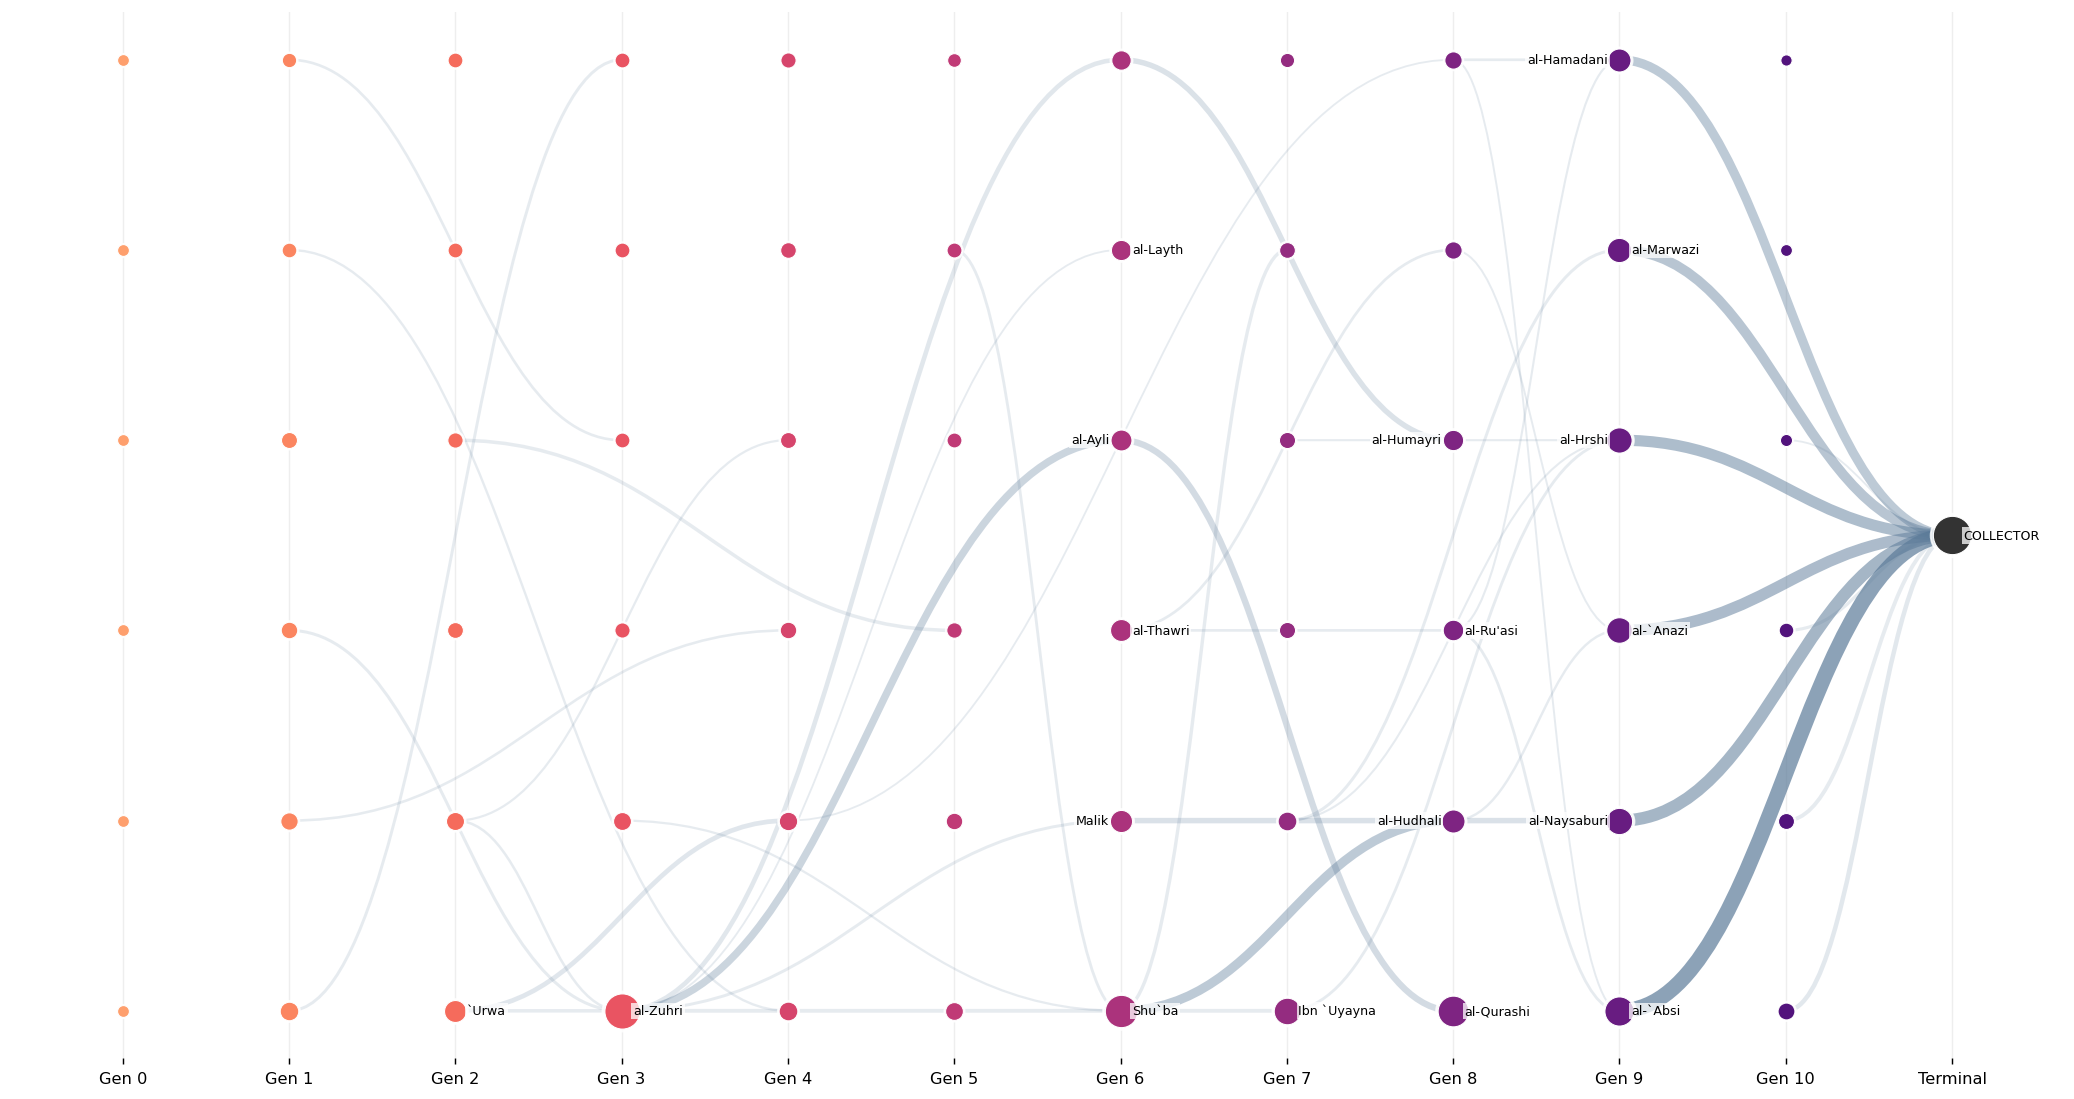

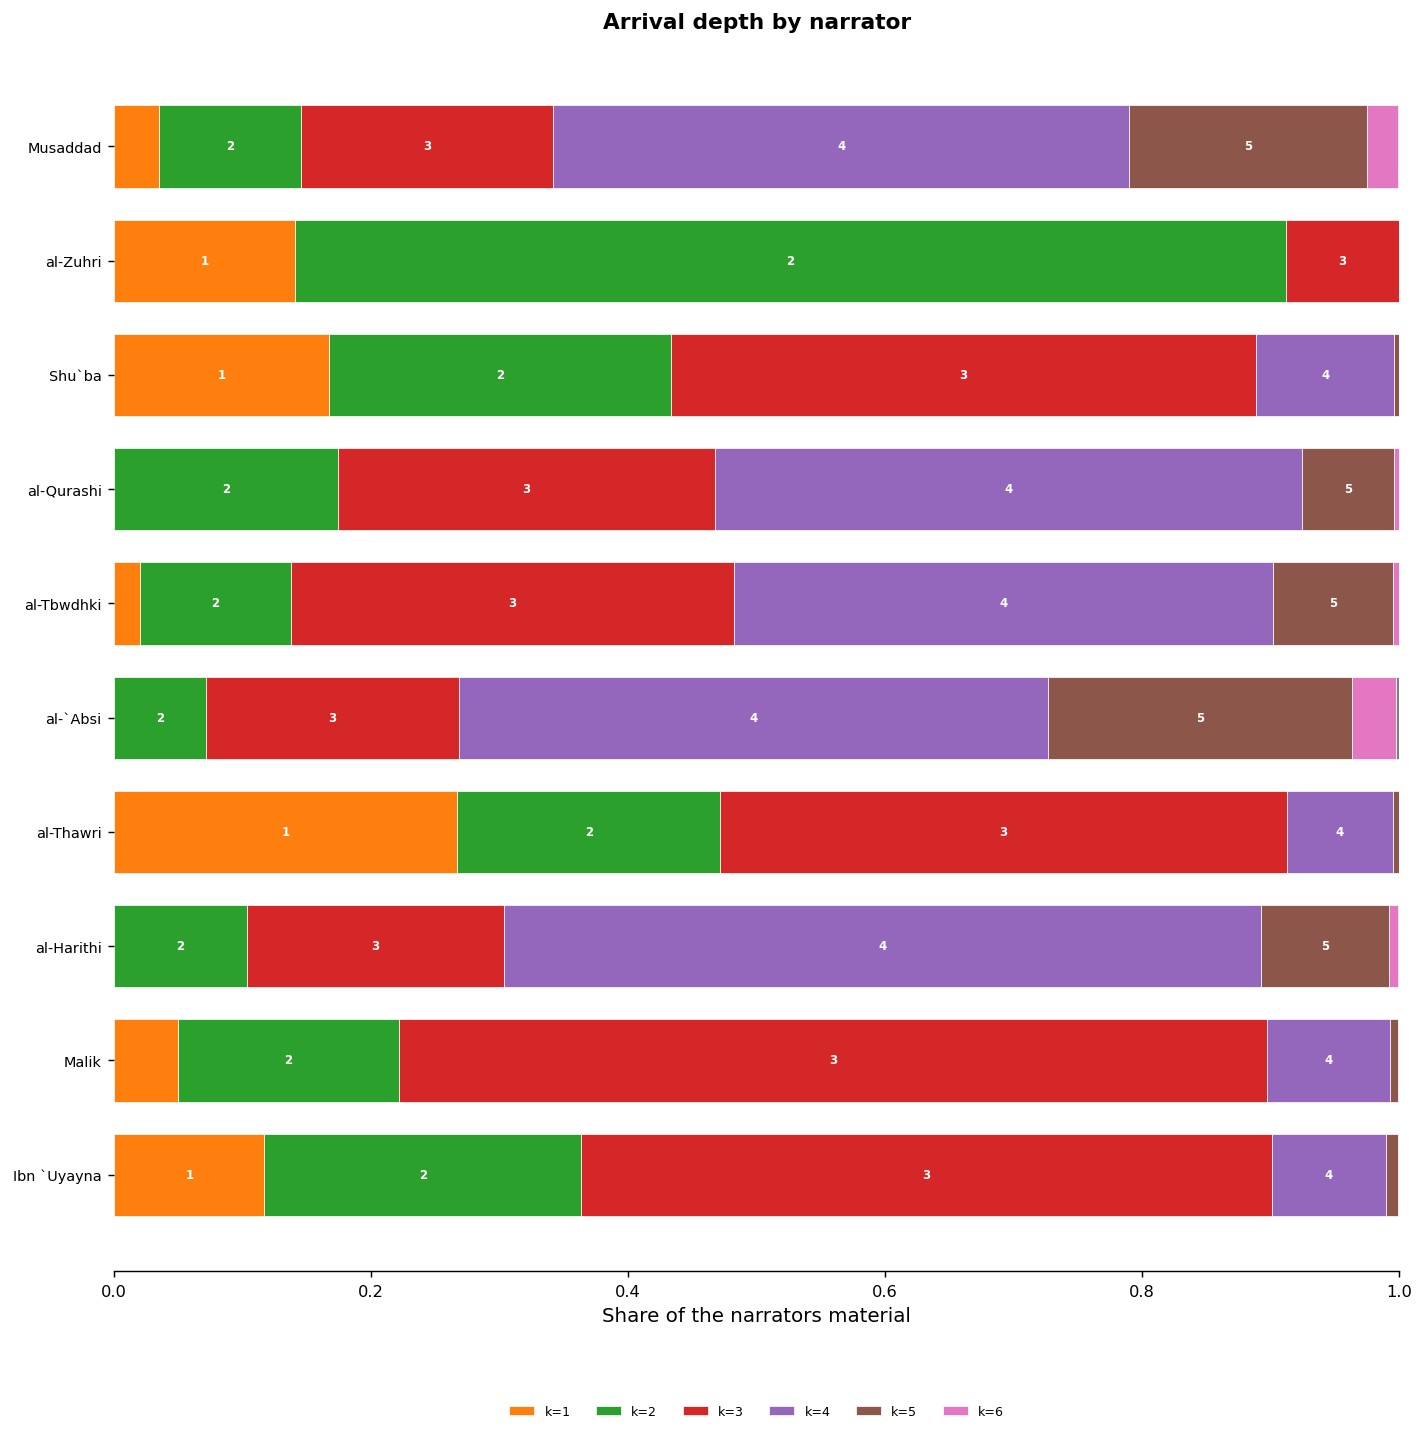

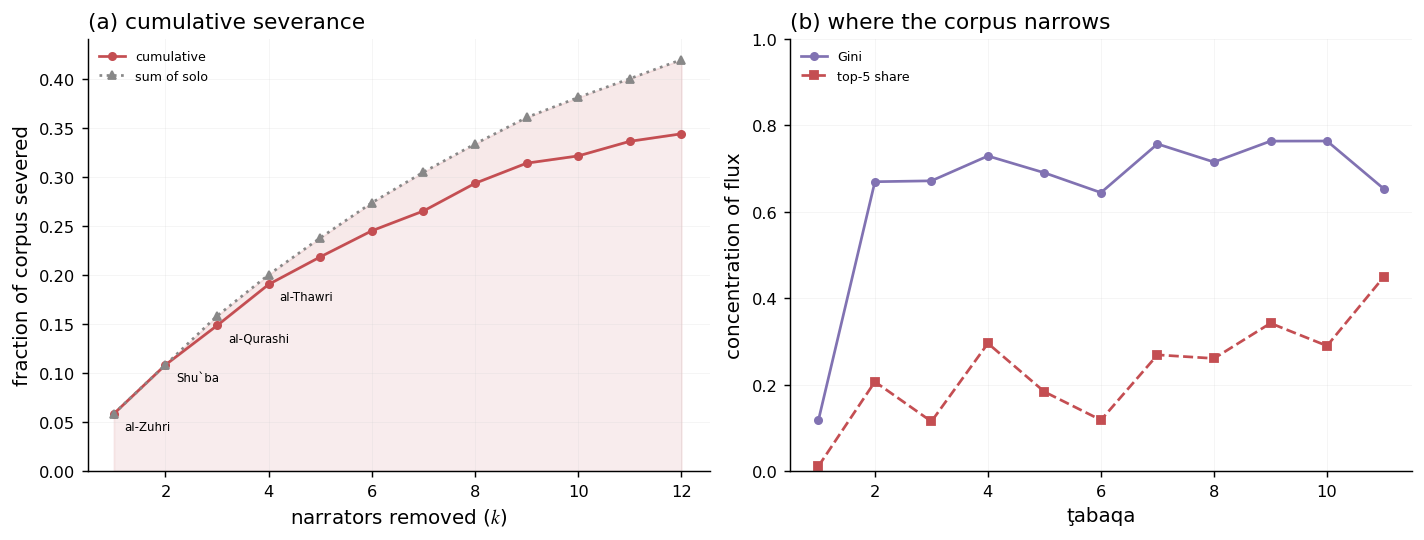

In [117]:
if __name__ == '__main__':
    print("Building model...")
    M = build_model()
    df, d = M['nodes_df'], M['diag']

    print(f"\n--- NETWORK DIAGNOSTICS ---")
    print(f"Nodes: {d['n_nodes']} | Vertical edges: {d['n_vertical_edges']}")
    print(f"Longest chain: {d['longest_chain']} hops")
    print(f"Roots: {d['n_roots']}  "
          f"(tabaqa 1: {d['roots_gen0']}, "
          f"max tabaqa: {d['roots_gen_max'] + 1:.0f}, "
          f"no generation: {d['roots_no_gen']})")

    print(f"\n--- PREPROCESSING DROPS (share of recorded transmissions) ---")
    print(f"Kept (vertical):            {d['kept_share']:.2%}")
    print(f"Lateral (same tabaqa):      {d['lateral_share']:.2%}")
    print(f"Over gen cap (>{d['gen_cap']}):        {d['over_gen_cap_share']:.2%}")
    print(f"Missing generation:         {d['no_generation_share']:.2%}")

    print(f"\n--- CONSERVATION ---")
    print(f"Injected:  {d['injected']:.1f}")
    print(f"Absorbed:  {d['absorbed']:.1f} ({d['absorbed']/d['injected']:.2%})")
    print(f"Stranded:  {d['stranded']:.1f} ({d['orphan_share']:.2%})")
    print(f"Unreached nodes: {d['unreached']}")
    print(f"Mean chain length: model {d['mean_chain_len_model']:.2f} hops | "
          f"empirical {d['mean_chain_len_empirical']:.2f}")

    print(f"Roots: {d['roots_gen0']: .1f}")

    print(f"\n--- ABLATION (VULNERABILITY) ---")
    abl = ablation(M)
    curve, solo, agg = abl
    print(curve.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    print(f"Top-5 solo sum: {agg['sum_solo']:.3f} | jointly: {agg['joint']:.3f}")
    print(concentration(M).to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    print(curve.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    print(f"\nTop-5 individually sever: {agg['sum_solo']:.3f} (Sum)")
    print(f"Top-5 jointly sever:      {agg['joint']:.3f} (Overlap)")

    print(f"\n--- CONCENTRATION ---")
    print(concentration(M).to_string(index=False, float_format=lambda x: f"{x:.4f}"))

    print(f"\n--- ULUWW ---")
    print(uluww_table(M).to_string(index=False,
      float_format=lambda x: f"{x:.3f}"))

    print(f"\n--- CENTRALITY CORRELATION ---")
    centrality_baseline(M, abl)


    print("\nGenerating Figures...")
    hop_profile(M)
    fig_ablation(M, abl)
    backbone(M)

In [102]:
def flux_2d(M, top=60, label_n=14, fname='fig_flux_muslim.jpg'):
    """x = share of own generation's flux (dominance within cohort)
    y = mean hops to arrival (how far the material actually travelled)
    size = share of the corpus,  colour = generation.

    All four are independent: a narrator can dominate a small late cohort
    (high x, low corpus share) or carry much of the corpus by sitting early
    in a crowded one (low x, large marker)."""
    d = M['nodes_df'].dropna(subset=['gen', 'mean_hops']).copy()
    if 'gen_share' not in d:
        d['gen_share'] = d.groupby('gen')['flux'].transform(
            lambda x: x / x.sum() if x.sum() > 0 else x)
    d = d.nlargest(top, 'flux')
    share = d.flux / M['S'].sum()

    with plt.rc_context(_STYLE):
        fig, ax = plt.subplots(figsize=(11, 7.5))

        p = ax.scatter(d.gen_share, d.mean_hops,
                       s=20 + 900 * share, c=d.gen,
                       alpha=0.8, edgecolor='white', lw=0.6, zorder=3)

        for r in d.nlargest(label_n, 'flux').itertuples():
            ax.annotate(short_name(r.name_en),
                        (r.gen_share, r.mean_hops),
                        textcoords='offset points', xytext=(0, 11),
                        ha='center', fontsize=7, zorder=4,
                        bbox=dict(facecolor='white', alpha=0.7,
                                  edgecolor='none', pad=0.8))

        ax.set_xscale('log')
        ax.set_xlabel("Share of own generation's flux")
        ax.set_ylabel('Mean hops to arrival')
        ax.set_title('Cohort dominance against transmission depth',
                     fontsize=12, weight='bold', pad=14)
        ax.grid(alpha=0.25, zorder=0)
        for s in ('top', 'right'):
            ax.spines[s].set_visible(False)

        cb = fig.colorbar(p, ax=ax, shrink=0.8)
        cb.set_label('Generation')

        # size legend — otherwise the most important encoding is unreadable
        for q in (0.02, 0.05, 0.15):
            ax.scatter([], [], s=20 + 900 * q, c='#888', alpha=0.6,
                       edgecolor='white', label=f'{q:.0%} of corpus')
        ax.legend(loc='upper left', frameon=False, fontsize=7,
                  labelspacing=1.4, borderpad=1.0, title='Flux share',
                  title_fontsize=7)

        fig.tight_layout()
        fig.savefig(fname, dpi=300, bbox_inches='tight')
    return d

In [10]:
flux_2d(M)

,narrator_id,name_en,gen,death_ah,flux,flux_share,nu_depth,mean_hops,orphan,gen_share
32,7272,Muhammad ibn Shihab al-Zuhri,3.0,52.0,29.292785,0.151776,4.482484,1.970852,False,0.404331
54,3795,Shu`ba ibn al-Hajjaj al-`Ataki,6.0,83.0,19.114670,0.099040,3.425630,2.643629,False,0.183221
31,6659,Malik ibn Anas al-Asbahi,6.0,89.0,12.022738,0.062294,3.046977,2.823665,False,0.115242
201,5594,`Urwa ibn Az-Zubayr al-Asadi,2.0,94.0,11.767826,0.060973,5.205978,1.231253,False,0.116262
73,3436,Sufyan ath-Thawri,6.0,97.0,10.470970,0.054254,3.296678,2.678051,False,0.100368
58,3443,Sufyan ibn `Uyayna al-Hilali,7.0,107.0,10.368874,0.053725,3.003767,2.765429,False,0.159634
19,7426,Msdd ibn Msrhd al-Asadi,9.0,228.0,9.081133,0.047053,2.000000,3.947487,False,0.082475
405,6641,al-Layth ibn Sa`d al-Fhmi,6.0,94.0,7.821674,0.040527,2.973131,3.509451,False,0.074974
12,5792,`Ali ibn al-Madini,9.0,161.0,7.700620,0.039900,2.000000,3.895178,False,0.069937
1090,8055,Hisham ibn `Urwa al-Asadi,4.0,58.0,7.669428,0.039738,4.039729,2.053251,False,0.133959
